In [62]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [64]:
df = pd.read_csv('/content/drive/MyDrive/Rayong2_Surface_Water_Quality_2018-2024.csv')

In [65]:
df.head()

,แม่น้ำ,ประเภทแหล่งน้ำ,Station,ปี,DO(mg/l),BOD(mg/l),TCB(MPN/100ml),FCB(MPN/100ml),NO3-N(mg/l),NH3-N(mg/l),WQI
0,แม่น้ำระยอง,4,RY01,2561,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2561,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2561,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2561,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2561,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [66]:
df.shape

(447, 11)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 447 entries, 0 to 446
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   แม่น้ำ          447 non-null    object 
 1   ประเภทแหล่งน้ำ  447 non-null    int64  
 2   Station         447 non-null    object 
 3   ปี              447 non-null    int64  
 4   DO(mg/l)        447 non-null    float64
 5   BOD(mg/l)       447 non-null    float64
 6   TCB(MPN/100ml)  447 non-null    object 
 7   FCB(MPN/100ml)  447 non-null    object 
 8   NO3-N(mg/l)     447 non-null    object 
 9   NH3-N(mg/l)     447 non-null    object 
 10  WQI             447 non-null    float64
dtypes: float64(3), int64(2), object(6)
memory usage: 38.5+ KB


In [68]:
df.describe()

,ประเภทแหล่งน้ำ,ปี,DO(mg/l),BOD(mg/l),WQI
count,447.000000,447.000000,447.000000,447.000000,447.000000
mean,3.129754,2564.248322,4.671521,1.649441,61.269821
std,0.596090,2.125774,1.514213,1.231552,11.904114
min,2.000000,2561.000000,0.470000,0.200000,26.690000
25%,3.000000,2562.000000,3.730000,1.000000,56.035000
50%,3.000000,2564.000000,4.800000,1.400000,60.220000
75%,3.500000,2566.000000,5.760000,1.800000,68.110000
max,4.000000,2567.000000,9.490000,16.100000,93.810000


In [69]:
df.isnull().sum()

,0
แม่น้ำ,0
ประเภทแหล่งน้ำ,0
Station,0
ปี,0
DO(mg/l),0
BOD(mg/l),0
TCB(MPN/100ml),0
FCB(MPN/100ml),0
NO3-N(mg/l),0
NH3-N(mg/l),0


In [70]:
df.columns

Index(['แม่น้ำ', 'ประเภทแหล่งน้ำ', 'Station', 'ปี', 'DO(mg/l)', 'BOD(mg/l)',
       'TCB(MPN/100ml)', 'FCB(MPN/100ml)', 'NO3-N(mg/l)', 'NH3-N(mg/l)',
       'WQI'],
      dtype='object')

In [71]:
df.columns = [
    "River",
    "Water_Type",
    "Station",
    "Year",
    "DO",
    "BOD",
    "TCB",
    "FCB",
    "NO3_N",
    "NH3_N",
    "WQI"
]

df.head()

,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
0,แม่น้ำระยอง,4,RY01,2561,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2561,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2561,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2561,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2561,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [72]:
df.columns = [
    "River", "Water_Type", "Station", "Year",
    "DO", "BOD", "TCB", "FCB", "NO3_N", "NH3_N", "WQI"
]

df['Year'] = pd.to_numeric(
    df['Year'], errors='raise'
)

df.loc[df['Year'] >= 2500, 'Year'] -= 543

assert df['Year'].between(2018, 2024).all(), \
    "Invalid year. Check the source CSV values."

print("Validated years in dataset:", sorted(df['Year'].unique()))
df.head()

Validated years in dataset: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
0,แม่น้ำระยอง,4,RY01,2018,6.86,1.4,"2,200",940,0.05,0.14,79.19
1,แม่น้ำระยอง,4,RY02,2018,5.17,1.4,"1,100",110,0.07,0.06,84.68
2,แม่น้ำระยอง,4,RY03,2018,0.95,2.2,"160,000","13,000",0.61,1.64,29.34
3,แม่น้ำระยอง,4,RY04,2018,3.32,1.6,"3,300",260,1.43,0.17,64.21
4,แม่น้ำระยอง,3,RY05,2018,2.91,1.6,"24,000","16,000",0.62,0.14,52.79


In [73]:
print("Total records:", len(df))

print("Number of rivers:", df["River"].nunique())

print("Number of stations:", df["Station"].nunique())

print("\nRecords by year:")

print(df["Year"].value_counts().sort_index())

Total records: 447
Number of rivers: 3
Number of stations: 27

Records by year:
Year
2018     60
2019     60
2020     60
2021     60
2022     45
2023     60
2024    102
Name: count, dtype: int64


Data Cleaning

In [74]:
df.duplicated().sum()

np.int64(0)

In [75]:
# Check duplicates excluding the year column

subset_columns = [
    col for col in df.columns
    if col != "Year"
]

duplicate_records = df[
    df.duplicated(
        subset=subset_columns,
        keep=False
    )
]

duplicate_records.sort_values(["Station", "Year"])

,River,Water_Type,Station,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
36,แม่น้ำประแสร์,3,PE01,2018,6.34,1.1,"9,200","3,500",0.23,0.28,70.84
321,แม่น้ำประแสร์,3,PE01,2023,6.34,1.1,"9,200","3,500",0.23,0.28,70.84
37,แม่น้ำประแสร์,3,PE02,2018,6.17,1.4,"3,500",790,0.23,0.64,57.16
322,แม่น้ำประแสร์,3,PE02,2023,6.17,1.4,"3,500",790,0.23,0.64,57.16
38,แม่น้ำประแสร์,3,PE03,2018,6.19,0.9,"3,500",330,0.29,0.25,69.12
323,แม่น้ำประแสร์,3,PE03,2023,6.19,0.9,"3,500",330,0.29,0.25,69.12
39,แม่น้ำประแสร์,3,PE04,2018,6.37,0.8,"9,200",78,0.31,0.45,67.74
324,แม่น้ำประแสร์,3,PE04,2023,6.37,0.8,"9,200",78,0.31,0.45,67.74
40,แม่น้ำประแสร์,3,PE05,2018,6.95,1.1,"5,400",330,0.23,0.29,68.11
325,แม่น้ำประแสร์,3,PE05,2023,6.95,1.1,"5,400",330,0.23,0.29,68.11


In [76]:
df = df.sort_values("Year", kind="stable")

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Remaining records:", len(df))

Remaining records: 447


In [77]:
duplicate_records["Year"].value_counts().sort_index()

,count
Year,
2018,15
2023,15


In [78]:
parameters = [
    "DO",
    "BOD",
    "TCB",
    "FCB",
    "NO3_N",
    "NH3_N"
]

for col in parameters:

    values = df[col].astype(str)
    values = values.str.replace(",", "", regex=False)

    numeric = pd.to_numeric(
        values,
        errors="coerce"
    )

    print(col, ":", values[numeric.isna()].unique())

DO : []
BOD : []
TCB : ['<18' '>160000']
FCB : ['<18']
NO3_N : ['<0.02' 'q2']
NH3_N : ['<0.03']


In [79]:
for col in parameters:

    values = df[col].astype(str).str.strip()

    values = values.str.replace(
        ",", "", regex=False
    )

    below_limit = values.str.startswith("<")

    numeric_values = pd.to_numeric(
        values.str.replace(
            r"^[<>]\s*", "", regex=True
        ),
        errors="coerce"
    ).astype(float)

    numeric_values.loc[below_limit] = (
        numeric_values.loc[below_limit] / 2
    )

    df[col] = numeric_values

In [80]:
df.isnull().sum()

,0
River,0
Water_Type,0
Station,0
Year,0
DO,0
BOD,0
TCB,0
FCB,0
NO3_N,1
NH3_N,0


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 447 entries, 0 to 446
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   River       447 non-null    object 
 1   Water_Type  447 non-null    int64  
 2   Station     447 non-null    object 
 3   Year        447 non-null    int64  
 4   DO          447 non-null    float64
 5   BOD         447 non-null    float64
 6   TCB         447 non-null    float64
 7   FCB         447 non-null    float64
 8   NO3_N       446 non-null    float64
 9   NH3_N       447 non-null    float64
 10  WQI         447 non-null    float64
dtypes: float64(7), int64(2), object(2)
memory usage: 38.5+ KB


In [82]:
df.describe()

,Water_Type,Year,DO,BOD,TCB,FCB,NO3_N,NH3_N,WQI
count,447.000000,447.000000,447.000000,447.000000,447.000000,447.000000,446.000000,447.000000,447.000000
mean,3.129754,2021.248322,4.671521,1.649441,19612.487696,3606.299776,0.431771,0.747685,61.269821
std,0.596090,2.125774,1.514213,1.231552,39299.889844,14536.372700,0.369570,1.381155,11.904114
min,2.000000,2018.000000,0.470000,0.200000,9.000000,9.000000,0.010000,0.015000,26.690000
25%,3.000000,2019.000000,3.730000,1.000000,790.000000,130.000000,0.120000,0.280000,56.035000
50%,3.000000,2021.000000,4.800000,1.400000,3500.000000,340.000000,0.390000,0.560000,60.220000
75%,3.500000,2023.000000,5.760000,1.800000,16000.000000,1700.000000,0.637500,0.900000,68.110000
max,4.000000,2024.000000,9.490000,16.100000,160000.000000,160000.000000,3.150000,26.700000,93.810000


,Feature,Importance,SD
0,DO,0.331106,0.059396
1,BOD,0.186767,0.033514
2,TCB,0.117376,0.042305
5,NH3_N,0.074992,0.014272
4,NO3_N,0.005848,0.006432
3,FCB,-0.000032,0.002616


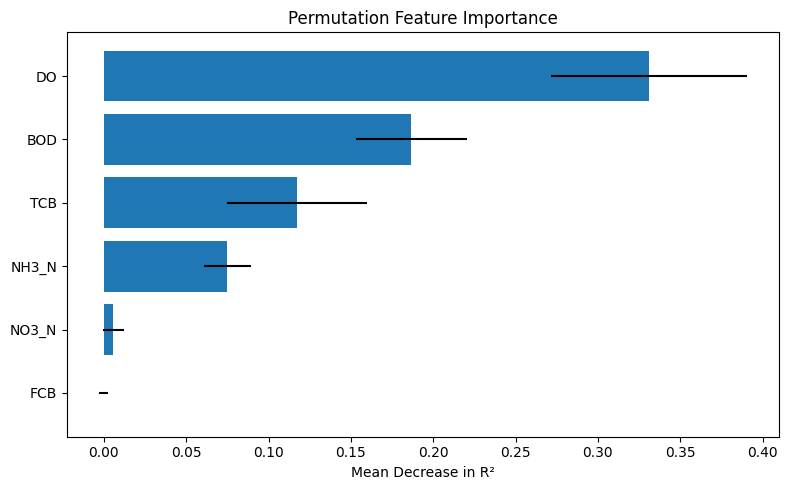

In [83]:
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure scenarios and target are defined
scenarios = {
    'A - Full Features': [
        'DO', 'BOD', 'TCB',
        'FCB', 'NO3_N', 'NH3_N'
    ],
    'B - EDA Based': [
        'DO', 'BOD', 'NH3_N'
    ],
    'C - DO Only': [
        'DO'
    ],
    'D - ML Based': [
        'DO', 'BOD', 'TCB'
    ]
}

full_features = scenarios['A - Full Features']
target = 'WQI'

# Perform split on the master cleaned df directly to avoid dependency issues
fit_df, validation_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

importance_model = make_pipeline(
    SimpleImputer(strategy='median'),
    LinearRegression()
)

importance_model.fit(
    fit_df[full_features],
    fit_df[target]
)

importance = permutation_importance(
    importance_model,
    validation_df[full_features],
    validation_df[target],
    n_repeats=30,
    random_state=42,
    scoring='r2'
)

importance_df = pd.DataFrame({
    'Feature': full_features,
    'Importance': importance.importances_mean,
    'SD': importance.importances_std
}).sort_values('Importance', ascending=False)

display(importance_df)

plt.figure(figsize=(8, 5))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    xerr=importance_df['SD']
)

plt.gca().invert_yaxis()
plt.xlabel('Mean Decrease in R²')
plt.title('Permutation Feature Importance')
plt.tight_layout()
plt.show()

# Select top three features for Scenario D
scenarios['D - ML Based'] = (
    importance_df['Feature'].head(3).tolist()
)

In [84]:
scenarios = {
    'A - Full Features': [
        'DO', 'BOD', 'TCB',
        'FCB', 'NO3_N', 'NH3_N'
    ],

    'B - EDA Based': [
        'DO', 'BOD', 'NH3_N'
    ],

    'C - DO Only': [
        'DO'
    ]
}

Train-Test Split

In [85]:
target = 'WQI'

df[target] = pd.to_numeric(
    df[target], errors='coerce'
)

df = df.dropna(subset=[target]).copy()

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

y_train = train_df[target]
y_test = test_df[target]

print('Training samples:', len(train_df))
print('Testing samples:', len(test_df))

Training samples: 357
Testing samples: 90


In [86]:
baseline = DummyRegressor(strategy='mean')

baseline.fit(train_df[['DO']], y_train)

y_baseline = baseline.predict(test_df[['DO']])

results = [{
    'Model': 'Mean Baseline',
    'R2': r2_score(y_test, y_baseline),
    'MAE': mean_absolute_error(y_test, y_baseline),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_baseline))
}]

pd.DataFrame(results)

,Model,R2,MAE,RMSE
0,Mean Baseline,-0.0328,8.978222,12.327279


In [87]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

predictions = {}
models = {}

# Keep only the baseline result
results = results[:1]

for name, features in scenarios.items():

    X_train = train_df[features]
    X_test = test_df[features]

    model = make_pipeline(
        SimpleImputer(strategy='median'),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    models[name] = model
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, y_pred)
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,R2,MAE,RMSE
0,Mean Baseline,-0.0328,8.9782,12.3273
1,A - Full Features,0.6252,5.8378,7.4259
2,B - EDA Based,0.6359,5.6173,7.3196
3,C - DO Only,0.3490,7.4856,9.7869


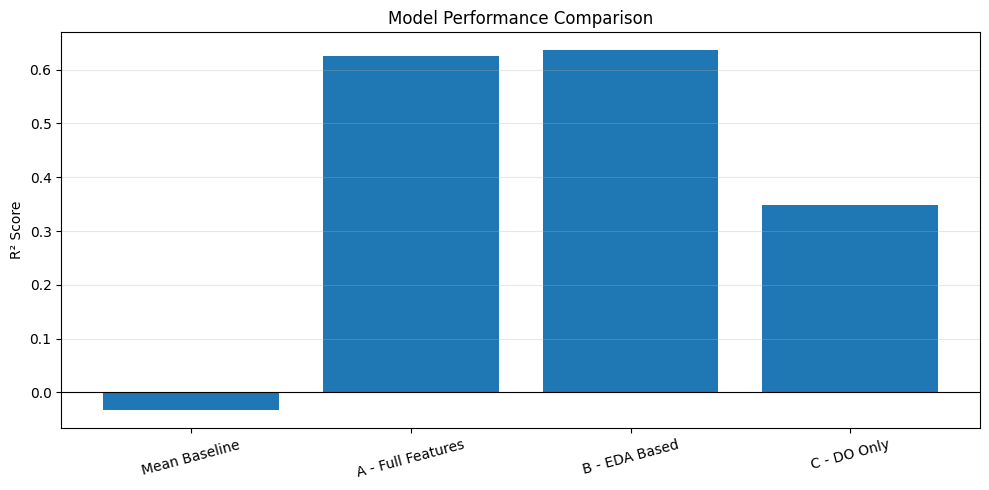

In [88]:
plt.figure(figsize=(10, 5))

plt.bar(results_df['Model'], results_df['R2'])

plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('R² Score')
plt.title('Model Performance Comparison')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

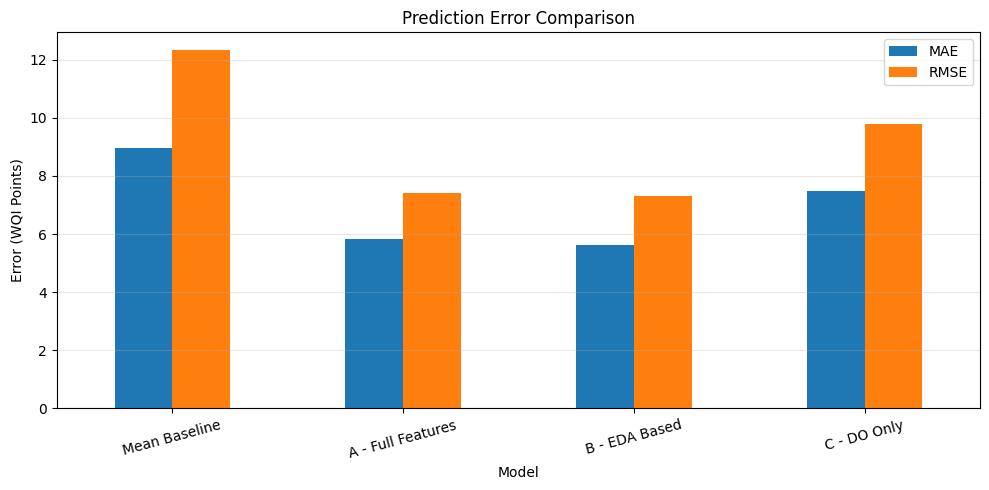

In [89]:
results_df.set_index('Model')[['MAE', 'RMSE']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Prediction Error Comparison')
plt.ylabel('Error (WQI Points)')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

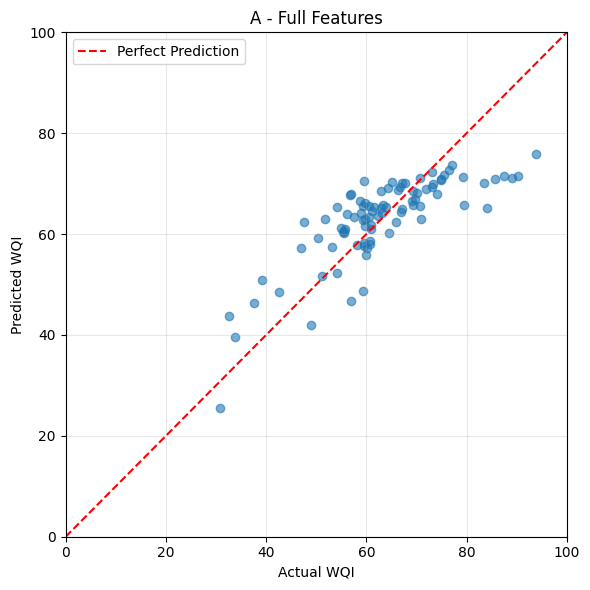

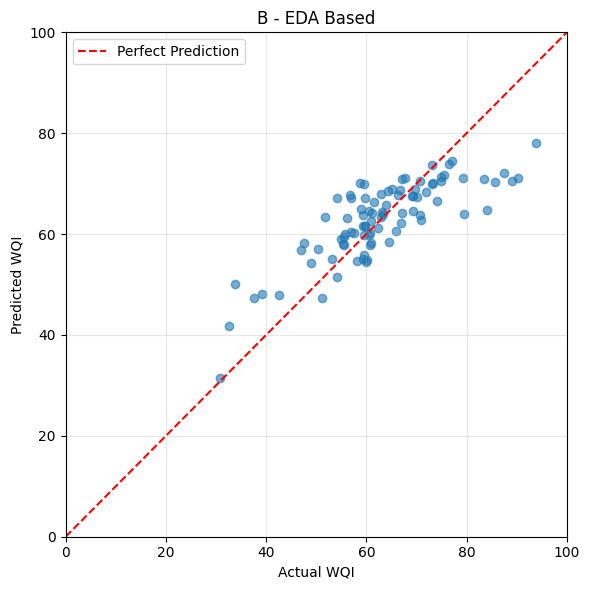

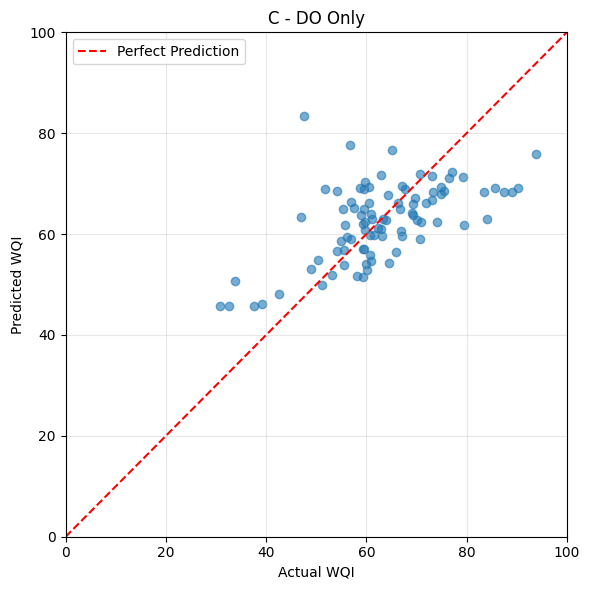

In [90]:
for name, y_pred in predictions.items():

    plt.figure(figsize=(6, 6))

    plt.scatter(y_test, y_pred, alpha=0.6)

    plt.plot([0, 100], [0, 100],
             'r--', label='Perfect Prediction')

    plt.xlim(0, 100)
    plt.ylim(0, 100)

    plt.xlabel('Actual WQI')
    plt.ylabel('Predicted WQI')
    plt.title(name)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [91]:
features = ['DO', 'BOD', 'NH3_N']

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df['WQI']
y_test = test_df['WQI']

In [92]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

final_models = {
    'Linear Regression': LinearRegression(),

    'Polynomial Regression': make_pipeline(
        PolynomialFeatures(degree=2),
        LinearRegression()
    ),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

In [93]:
from sklearn.model_selection import cross_validate

final_results = []

for name, model in final_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            'R2': 'r2',
            'MAE': 'neg_mean_absolute_error',
            'RMSE': 'neg_root_mean_squared_error'
        }
    )

    final_results.append({
        'Model': name,
        'R2': scores['test_R2'].mean(),
        'MAE': -scores['test_MAE'].mean(),
        'RMSE': -scores['test_RMSE'].mean()
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Model,R2,MAE,RMSE
0,Linear Regression,-0.6406,6.3970,12.1286
1,Polynomial Regression,-137.9037,12.4366,66.1380
2,Decision Tree,0.6549,4.9334,6.7523
3,Random Forest,0.7034,4.5922,6.2364


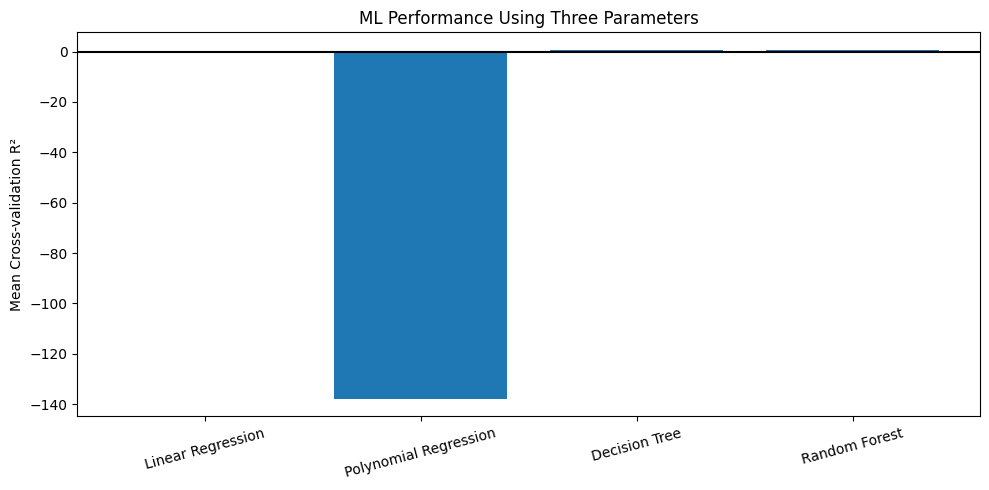

In [94]:
plt.figure(figsize=(10, 5))

plt.bar(
    final_results_df['Model'],
    final_results_df['R2']
)

plt.ylabel('Mean Cross-validation R²')
plt.title('ML Performance Using Three Parameters')
plt.xticks(rotation=15)
plt.axhline(0, color='black')
plt.tight_layout()
plt.show()

In [95]:
best_name = final_results_df.loc[
    final_results_df['R2'].idxmax(), 'Model'
]

best_model = final_models[best_name]

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print('Best Model:', best_name)
print('R2:', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

Best Model: Random Forest
R2: 0.764234317542827
MAE: 4.33718222222222
RMSE: 5.889784755678447


In [96]:
def classify_wqi(wqi):
    if wqi <= 30:
        return 'Very Poor'
    elif wqi <= 60:
        return 'Poor'
    elif wqi <= 70:
        return 'Fair'
    elif wqi <= 90:
        return 'Good'
    else:
        return 'Excellent'

evaluation_df = pd.DataFrame({
    'Actual WQI': np.asarray(y_test),
    'Predicted WQI': y_pred
})

evaluation_df['Actual Class'] = (
    evaluation_df['Actual WQI'].apply(classify_wqi)
)

evaluation_df['Predicted Class'] = (
    evaluation_df['Predicted WQI'].apply(classify_wqi)
)

display(evaluation_df.head(10))

,Actual WQI,Predicted WQI,Actual Class,Predicted Class
0,59.76,56.0838,Poor,Poor
1,56.76,67.4317,Poor,Fair
2,66.64,67.3495,Fair,Fair
3,51.12,46.2334,Poor,Poor
4,63.41,56.5374,Fair,Poor
5,60.75,59.4732,Fair,Poor
6,70.61,66.6748,Good,Fair
7,42.55,40.3582,Poor,Poor
8,60.56,60.3981,Fair,Fair
9,59.58,71.2849,Poor,Good


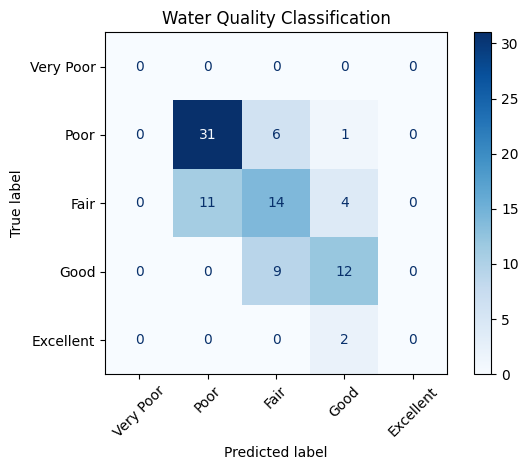

              precision    recall  f1-score   support

   Very Poor       0.00      0.00      0.00         0
        Poor       0.74      0.82      0.78        38
        Fair       0.48      0.48      0.48        29
        Good       0.63      0.57      0.60        21
   Excellent       0.00      0.00      0.00         2

    accuracy                           0.63        90
   macro avg       0.37      0.37      0.37        90
weighted avg       0.61      0.63      0.62        90



In [97]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

labels = ['Very Poor', 'Poor', 'Fair', 'Good', 'Excellent']

cm = confusion_matrix(
    evaluation_df['Actual Class'],
    evaluation_df['Predicted Class'],
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues', xticks_rotation=45)

plt.title('Water Quality Classification')
plt.tight_layout()
plt.show()

print(classification_report(
    evaluation_df['Actual Class'],
    evaluation_df['Predicted Class'],
    labels=labels,
    zero_division=0
))

In [98]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

actual_pollution = y_test <= 60
predicted_pollution = y_pred <= 60

print('Accuracy:', accuracy_score(
    actual_pollution, predicted_pollution))

print('Precision:', precision_score(
    actual_pollution, predicted_pollution,
    zero_division=0))

print('Recall:', recall_score(
    actual_pollution, predicted_pollution,
    zero_division=0))

print('F1 Score:', f1_score(
    actual_pollution, predicted_pollution,
    zero_division=0))

Accuracy: 0.8
Precision: 0.7380952380952381
Recall: 0.8157894736842105
F1 Score: 0.775


In [99]:
water = df[
    ['River', 'Station', 'Year',
     'DO', 'BOD', 'NH3_N', 'WQI']
].copy()

water['River'] = water['River'].replace({
    'แม่น้ำระยอง': 'Rayong',
    'แม่น้ำประแสร์': 'Prasae',
    'แม่น้ำพังราด': 'Phang Rat'
})

water['Poor'] = water['WQI'] <= 60

display(water.head())

print('Total records:', len(water))

,River,Station,Year,DO,BOD,NH3_N,WQI,Poor
0,Rayong,RY01,2018,6.86,1.4,0.14,79.19,False
1,Rayong,RY02,2018,5.17,1.4,0.06,84.68,False
2,Rayong,RY03,2018,0.95,2.2,1.64,29.34,True
3,Rayong,RY04,2018,3.32,1.6,0.17,64.21,False
4,Rayong,RY05,2018,2.91,1.6,0.14,52.79,True


Total records: 447


In [100]:
river_summary = water.groupby('River').agg(
    Average_WQI=('WQI', 'mean'),
    Poor_Percentage=('Poor', 'mean'),
    Average_DO=('DO', 'mean'),
    Average_BOD=('BOD', 'mean'),
    Average_NH3=('NH3_N', 'mean'),
    Records=('WQI', 'count')
)

river_summary['Poor_Percentage'] *= 100

river_summary = river_summary.sort_values('Average_WQI')

display(river_summary.round(2))

,Average_WQI,Poor_Percentage,Average_DO,Average_BOD,Average_NH3,Records
River,,,,,,
Rayong,57.55,62.50,4.01,1.75,0.76,176
Phang Rat,61.21,47.97,4.94,1.73,0.95,123
Prasae,65.75,32.43,5.23,1.46,0.56,148


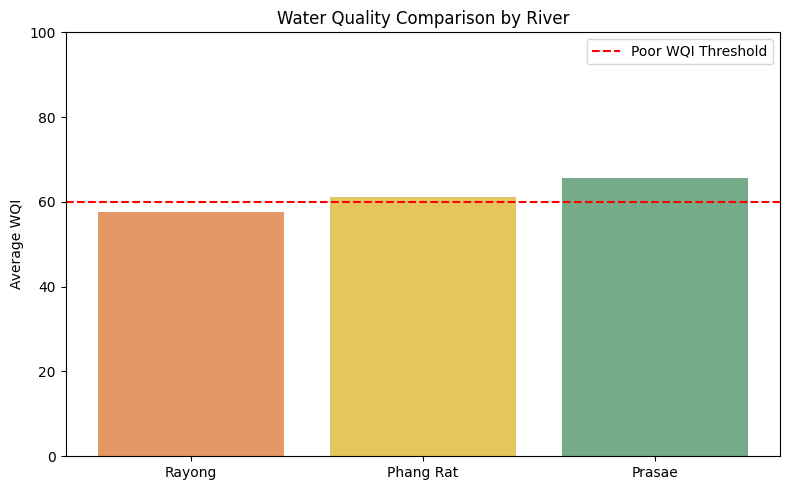

In [101]:
plt.figure(figsize=(8, 5))

plt.bar(
    river_summary.index,
    river_summary['Average_WQI'],
    color=['#E59866', '#E5C65C', '#75AB89']
)

plt.axhline(60, color='red', linestyle='--',
            label='Poor WQI Threshold')

plt.ylabel('Average WQI')
plt.title('Water Quality Comparison by River')
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

In [102]:
station_summary = water.groupby(
    ['River', 'Station']
).agg(
    Average_WQI=('WQI', 'mean'),
    Poor_Percentage=('Poor', 'mean'),
    Average_DO=('DO', 'mean'),
    Average_BOD=('BOD', 'mean'),
    Average_NH3=('NH3_N', 'mean'),
    Years=('Year', 'nunique'),
    Records=('WQI', 'count')
).reset_index()

station_summary['Poor_Percentage'] *= 100

station_summary = station_summary.sort_values('Average_WQI')

display(station_summary.round(2))

,River,Station,Average_WQI,Poor_Percentage,Average_DO,Average_BOD,Average_NH3,Years,Records
20,Rayong,RY03.5,45.19,100.00,2.75,2.02,1.78,1,4
4,Phang Rat,PR04,47.11,85.19,4.26,3.30,1.11,7,27
19,Rayong,RY03,48.72,96.30,2.79,1.78,1.06,7,27
15,Prasae,PE08,52.34,66.67,5.24,4.47,1.07,1,3
17,Rayong,RY01,57.38,66.67,4.19,1.62,1.02,7,27
18,Rayong,RY02,57.54,62.96,3.62,1.39,0.89,7,27
25,Rayong,RY05.5,58.11,33.33,2.70,3.20,0.28,1,3
7,Phang Rat,PR07,58.53,50.00,4.24,1.30,7.10,1,4
21,Rayong,RY04,58.57,62.96,3.68,1.71,0.66,7,27
5,Phang Rat,PR05,59.17,66.67,5.05,1.93,0.70,1,3


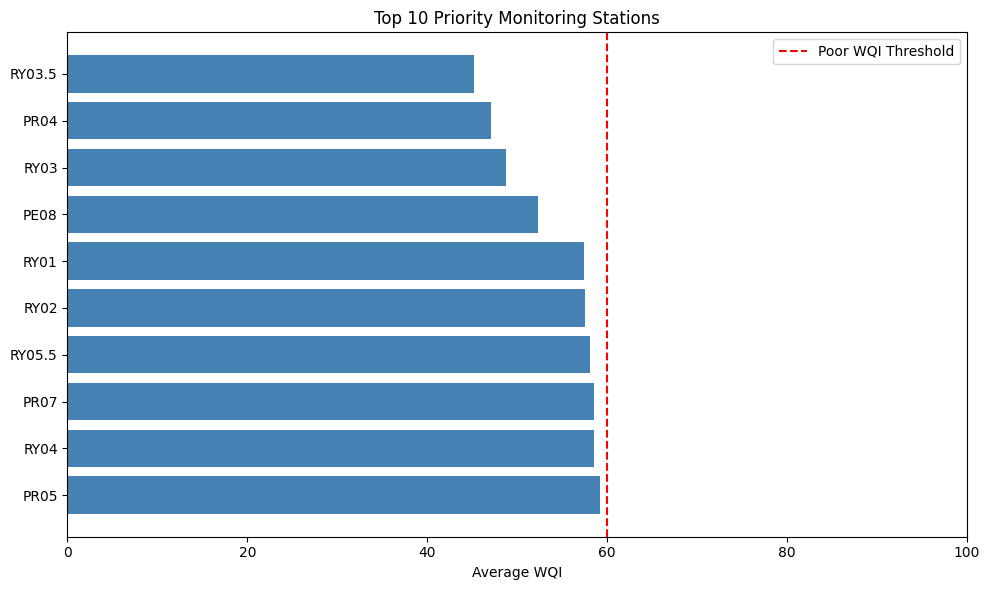

In [103]:
top10 = station_summary.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top10['Station'],
    top10['Average_WQI'],
    color='steelblue'
)

plt.gca().invert_yaxis()

plt.axvline(60, color='red', linestyle='--',
            label='Poor WQI Threshold')

plt.xlabel('Average WQI')
plt.title('Top 10 Priority Monitoring Stations')
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

In [104]:
long_term_stations = station_summary[
    station_summary['Years'] == 7
].copy()

long_term_stations = long_term_stations.sort_values(
    'Average_WQI'
)

display(long_term_stations.round(2))

,River,Station,Average_WQI,Poor_Percentage,Average_DO,Average_BOD,Average_NH3,Years,Records
4,Phang Rat,PR04,47.11,85.19,4.26,3.30,1.11,7,27
19,Rayong,RY03,48.72,96.30,2.79,1.78,1.06,7,27
17,Rayong,RY01,57.38,66.67,4.19,1.62,1.02,7,27
18,Rayong,RY02,57.54,62.96,3.62,1.39,0.89,7,27
21,Rayong,RY04,58.57,62.96,3.68,1.71,0.66,7,27
23,Rayong,RY05,59.99,57.69,4.30,1.84,0.48,7,26
10,Prasae,PE03,60.28,55.56,4.79,1.70,0.63,7,27
26,Rayong,RY06,63.39,29.63,5.33,1.81,0.49,7,27
3,Phang Rat,PR03,63.96,44.44,4.96,1.68,0.63,7,27
9,Prasae,PE02,64.76,33.33,5.24,1.52,0.57,7,27


In [105]:
annual_station = water.groupby(
    ['River', 'Station', 'Year']
)['WQI'].mean().reset_index()

annual_station['Poor_Year'] = annual_station['WQI'] <= 60

persistent = annual_station.groupby(
    ['River', 'Station']
).agg(
    Monitoring_Years=('Year', 'nunique'),
    Poor_Years=('Poor_Year', 'sum'),
    Average_Annual_WQI=('WQI', 'mean')
).reset_index()

persistent_hotspots = persistent[
    (persistent['Monitoring_Years'] == 7) &
    (persistent['Poor_Years'] == 7)
]

display(persistent_hotspots.round(2))

,River,Station,Monitoring_Years,Poor_Years,Average_Annual_WQI
4,Phang Rat,PR04,7,7,47.01
19,Rayong,RY03,7,7,48.81


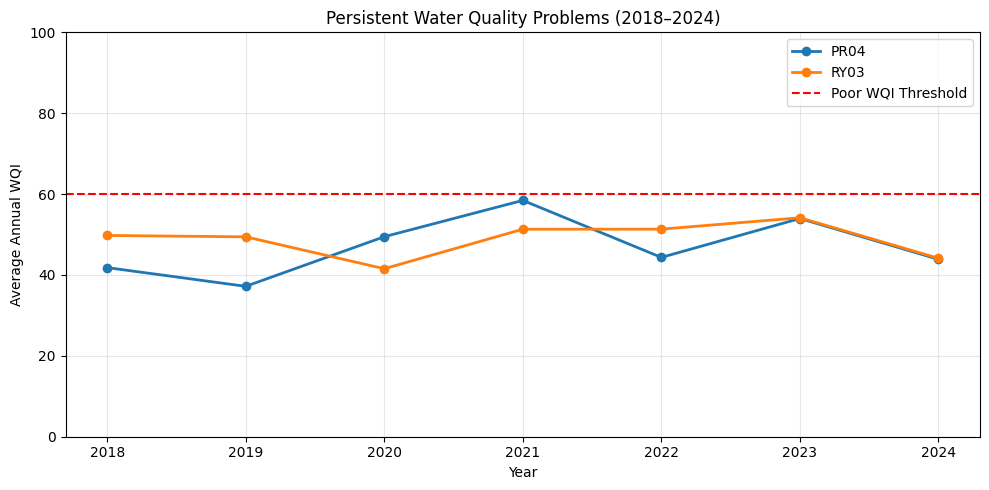

In [106]:
priority_stations = ['RY03', 'PR04']

priority_trends = annual_station[
    annual_station['Station'].isin(priority_stations)
]

trend_table = priority_trends.pivot(
    index='Year',
    columns='Station',
    values='WQI'
)

trend_table.plot(
    figsize=(10, 5),
    marker='o',
    linewidth=2
)

plt.axhline(60, color='red', linestyle='--',
            label='Poor WQI Threshold')

plt.ylabel('Average Annual WQI')
plt.title('Persistent Water Quality Problems (2018–2024)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [107]:
priority_summary = station_summary[
    station_summary['Station'].isin(priority_stations)
]

display(priority_summary[
    ['River', 'Station', 'Average_WQI',
     'Average_DO', 'Average_BOD', 'Average_NH3',
     'Poor_Percentage']
].round(2))

,River,Station,Average_WQI,Average_DO,Average_BOD,Average_NH3,Poor_Percentage
4,Phang Rat,PR04,47.11,4.26,3.30,1.11,85.19
19,Rayong,RY03,48.72,2.79,1.78,1.06,96.30


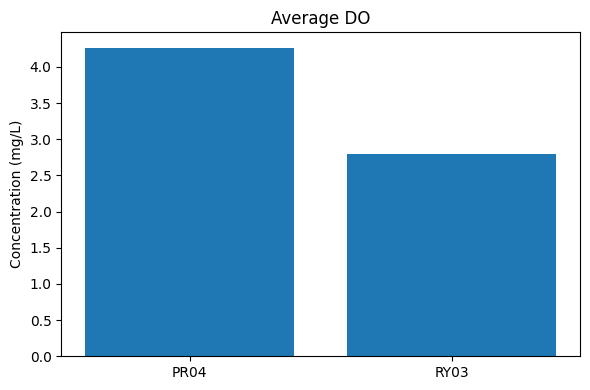

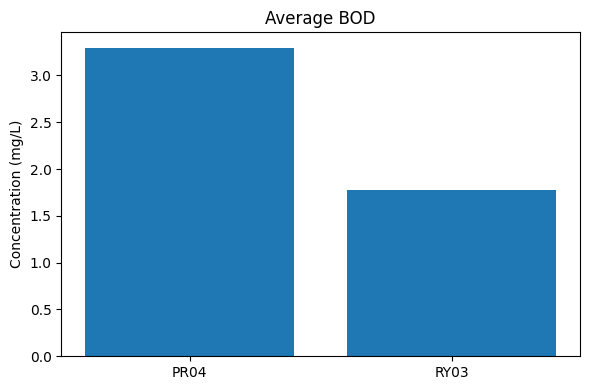

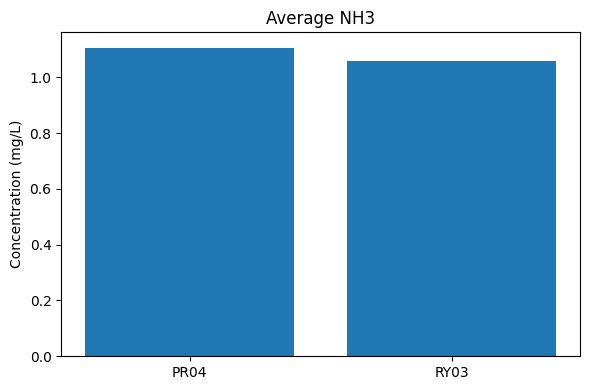

In [108]:
parameters = ['Average_DO', 'Average_BOD', 'Average_NH3']

for parameter in parameters:

    plt.figure(figsize=(6, 4))

    plt.bar(
        priority_summary['Station'],
        priority_summary[parameter]
    )

    plt.ylabel('Concentration (mg/L)')
    plt.title(parameter.replace('_', ' '))
    plt.tight_layout()
    plt.show()

In [109]:
target_wqi = 65

improvement = priority_summary[
    ['River', 'Station', 'Average_WQI']
].copy()

improvement['Target_WQI'] = target_wqi

improvement['Required_Improvement'] = (
    improvement['Target_WQI'] -
    improvement['Average_WQI']
)

display(improvement.round(2))

,River,Station,Average_WQI,Target_WQI,Required_Improvement
4,Phang Rat,PR04,47.11,65,17.89
19,Rayong,RY03,48.72,65,16.28


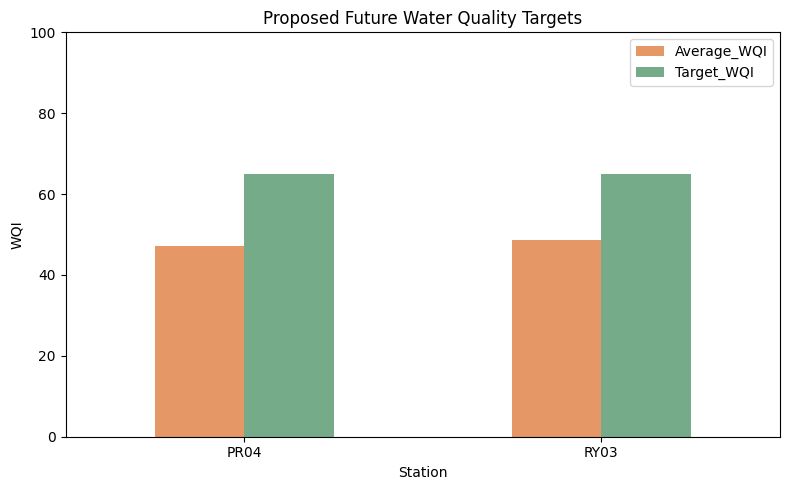

In [110]:
improvement.set_index('Station')[
    ['Average_WQI', 'Target_WQI']
].plot(
    kind='bar',
    figsize=(8, 5),
    color=['#E59866', '#75AB89']
)

plt.ylabel('WQI')
plt.title('Proposed Future Water Quality Targets')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [111]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

features = ['DO', 'BOD', 'NH3_N']

model_data = water.dropna(subset=features + ['WQI'])

# Dynamically split by the maximum available year in the dataset to avoid empty test sets
latest_year = model_data['Year'].max()
train_future = model_data[model_data['Year'] < latest_year]
test_future = model_data[model_data['Year'] == latest_year].copy()

future_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

future_model.fit(
    train_future[features],
    train_future['WQI']
)

test_future['Predicted_WQI'] = future_model.predict(
    test_future[features]
)

print('Test Year used:', latest_year)
print('R2:', r2_score(
    test_future['WQI'], test_future['Predicted_WQI']
))

print('MAE:', mean_absolute_error(
    test_future['WQI'], test_future['Predicted_WQI']
))

print('RMSE:', np.sqrt(mean_squared_error(
    test_future['WQI'], test_future['Predicted_WQI']
)))

Test Year used: 2024
R2: -322.946386594836
MAE: 23.506704462368287
RMSE: 186.9642107841273


In [112]:
lower = train_future[features].min()
upper = train_future[features].max()

test_future['Within_Range'] = (
    test_future[features].ge(lower).all(axis=1) &
    test_future[features].le(upper).all(axis=1)
)

outside_range = test_future[
    ~test_future['Within_Range']
]

display(outside_range[
    ['Station', 'DO', 'BOD', 'NH3_N',
     'WQI', 'Predicted_WQI']
].round(2))

,Station,DO,BOD,NH3_N,WQI,Predicted_WQI
378,RY05,9.49,6.9,0.70,47.52,44.06
426,RY01,5.17,1.1,6.30,46.98,91.38
429,RY03.5,4.44,1.8,3.92,46.64,52.38
446,PR07,3.09,1.2,26.70,47.73,1934.50


In [113]:
valid = test_future[test_future['Within_Range']]

print('Records within training range:', len(valid))

print('R2:', r2_score(
    valid['WQI'], valid['Predicted_WQI']
))

print('MAE:', mean_absolute_error(
    valid['WQI'], valid['Predicted_WQI']
))

print('RMSE:', np.sqrt(mean_squared_error(
    valid['WQI'], valid['Predicted_WQI']
)))

Records within training range: 98
R2: 0.6609781056715525
MAE: 4.6664614182616635
RMSE: 6.022426814080293


In [114]:
def estimate_wqi(DO, BOD, NH3_N):

    inputs = pd.DataFrame({
        'DO': [DO],
        'BOD': [BOD],
        'NH3_N': [NH3_N]
    })

    within_range = (
        inputs.ge(lower).all(axis=1) &
        inputs.le(upper).all(axis=1)
    ).iloc[0]

    if not within_range:
        print('Warning: Outside training range.')
        print('Full laboratory testing recommended.')
        return

    prediction = future_model.predict(inputs)[0]

    if not 0 <= prediction <= 100:
        print('Invalid WQI prediction. Further testing needed.')
        return

    print('Estimated WQI:', round(prediction, 2))

    if prediction <= 30:
        category = 'Very Poor'
    elif prediction <= 60:
        category = 'Poor'
    elif prediction <= 70:
        category = 'Fair'
    elif prediction <= 90:
        category = 'Good'
    else:
        category = 'Excellent'

    print('Water Quality:', category)

    if prediction <= 60:
        print('Recommendation: Priority investigation')
    else:
        print('Recommendation: Continue monitoring')

    print('Preliminary estimate only.')

In [115]:
estimate_wqi(
    DO=3.0,
    BOD=2.5,
    NH3_N=1.2
)

Estimated WQI: 46.2
Water Quality: Poor
Recommendation: Priority investigation
Preliminary estimate only.


Scenario Analysis

In [116]:
scenario_results = []

for _, row in priority_summary.iterrows():

    for change in [0, 10, 20, 30, 40, 50]:

        inputs = pd.DataFrame({
            'DO': [
                row['Average_DO'] * (1 + change/100)
            ],
            'BOD': [
                row['Average_BOD'] * (1 - change/100)
            ],
            'NH3_N': [
                row['Average_NH3'] * (1 - change/100)
            ]
        })

        within_range = (
            inputs.ge(lower).all(axis=1) &
            inputs.le(upper).all(axis=1)
        ).iloc[0]

        if not within_range:
            continue

        predicted_wqi = future_model.predict(inputs)[0]

        if not 0 <= predicted_wqi <= 100:
            continue

        scenario_results.append({
            'Station': row['Station'],
            'Improvement_Percent': change,
            'DO': inputs['DO'].iloc[0],
            'BOD': inputs['BOD'].iloc[0],
            'NH3_N': inputs['NH3_N'].iloc[0],
            'Predicted_WQI': predicted_wqi
        })

scenario_df = pd.DataFrame(scenario_results)

display(scenario_df.round(2))

,Station,Improvement_Percent,DO,BOD,NH3_N,Predicted_WQI
0,PR04,0,4.26,3.30,1.11,47.10
1,PR04,10,4.69,2.97,1.00,50.63
2,PR04,20,5.12,2.64,0.88,54.28
3,PR04,30,5.54,2.31,0.77,58.05
4,PR04,40,5.97,1.98,0.66,61.93
5,PR04,50,6.40,1.65,0.55,65.93
6,RY03,0,2.79,1.78,1.06,49.90
7,RY03,10,3.07,1.60,0.95,52.63
8,RY03,20,3.35,1.43,0.85,55.46
9,RY03,30,3.63,1.25,0.74,58.40


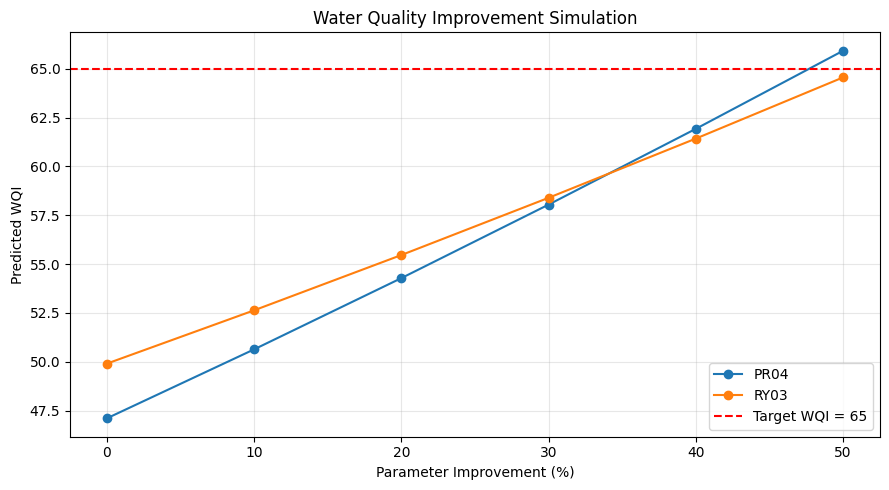

In [117]:
plt.figure(figsize=(9, 5))

for station, group in scenario_df.groupby('Station'):

    plt.plot(
        group['Improvement_Percent'],
        group['Predicted_WQI'],
        marker='o',
        label=station
    )

plt.axhline(
    65,
    color='red',
    linestyle='--',
    label='Target WQI = 65'
)

plt.xlabel('Parameter Improvement (%)')
plt.ylabel('Predicted WQI')
plt.title('Water Quality Improvement Simulation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [118]:
achievable = scenario_df[
    scenario_df['Predicted_WQI'] >= 65
].copy()

target_results = achievable.sort_values(
    'Improvement_Percent'
).groupby('Station').head(1)

display(target_results.round(2))

,Station,Improvement_Percent,DO,BOD,NH3_N,Predicted_WQI
5,PR04,50,6.4,1.65,0.55,65.93
